In [2]:
# Setup: imports, file paths, memmap helpers
import numpy as np
import matplotlib.pyplot as plt
import os
from numpy.fft import fft, fftshift, fftfreq

# Notebook plotting defaults
%matplotlib inline
plt.rcParams.update({
    'figure.figsize': (12, 4),
    'axes.grid': True
})

# Data config (adjust path if needed)
filename = '../ds2.bin'  # path relative to this notebook
fs = 25_000_000          # sample rate (Hz)
bytes_per_sample = 4     # 2 bytes I + 2 bytes Q (int16)

# Analysis window in seconds
t_start = 60.0
t_end   = 300.0
assert t_end > t_start, 't_end must be > t_start'

# File checks
if not os.path.exists(filename):
    raise FileNotFoundError(f'Arquivo não encontrado: {filename}')

total_bytes = os.path.getsize(filename)
N_int16 = total_bytes // 2
N_samples = total_bytes // bytes_per_sample  # complex samples (I,Q)
print(f'Arquivo: {filename}\n- Tamanho: {total_bytes:,} bytes\n- Amostras complexas: {N_samples:,}\n- Duração aprox: {N_samples/fs:.2f} s')

# Open memmap once (read-only)
mm = np.memmap(filename, dtype=np.int16, mode='r', shape=(N_int16,))

# Helper: read a short complex window centered at time t (seconds)
# Returns complex64 array of length win_N
# Guard-rails: clamps to file bounds

def read_window_at_time(t_sec: float, win_N: int) -> np.ndarray:
    ctr = int(t_sec * fs)
    half = win_N // 2
    start = max(0, ctr - half)
    end = min(N_samples, start + win_N)
    # ensure exact length when near boundaries
    start = max(0, end - win_N)
    i0 = 2 * start
    i1 = 2 * end
    seg = mm[i0:i1]
    I = seg[0::2].astype(np.float32)
    Q = seg[1::2].astype(np.float32)
    return I + 1j * Q

# Helper: integrate power in a 2 MHz band around DC via FFT
# Returns linear power and power in dB

def inband_power_2mhz(x: np.ndarray) -> tuple[float, float]:
    N = len(x)
    # Hann window to reduce spectral leakage
    w = np.hanning(N).astype(np.float32)
    X = fftshift(fft(x * w))
    freqs = fftshift(fftfreq(N, d=1/fs))
    mask = np.abs(freqs) <= 1_000_000.0  # ±1 MHz band
    # Power spectral density ~ |X|^2, integrate over selected bins
    p_lin = float(np.sum(np.abs(X[mask])**2) / np.sum(w**2))
    p_db = 10.0 * np.log10(p_lin + 1e-20)
    return p_lin, p_db

# Helper: spectral centroid within ±1 MHz as Doppler proxy (Hz)

def doppler_proxy_centroid(x: np.ndarray) -> float:
    N = len(x)
    w = np.hanning(N).astype(np.float32)
    X = fftshift(fft(x * w))
    freqs = fftshift(fftfreq(N, d=1/fs))
    mask = np.abs(freqs) <= 1_000_000.0
    P = (np.abs(X)**2)[mask]
    F = freqs[mask]
    denom = float(np.sum(P)) + 1e-30
    return float(np.sum(F * P) / denom)

# Helper: lag-1 normalized autocorr phase (phase-perturbation proxy)

def lag1_autocorr_phase(x: np.ndarray) -> float:
    # Normalize to unit power to make measure scale-invariant
    if len(x) < 2:
        return 0.0
    xn = x / (np.sqrt(np.mean(np.abs(x)**2)) + 1e-20)
    r1 = np.vdot(xn[:-1], xn[1:]) / (len(xn) - 1)
    return float(np.angle(r1))


Arquivo: ../ds2.bin
- Tamanho: 45,717,913,600 bytes
- Amostras complexas: 11,429,478,400
- Duração aprox: 457.18 s


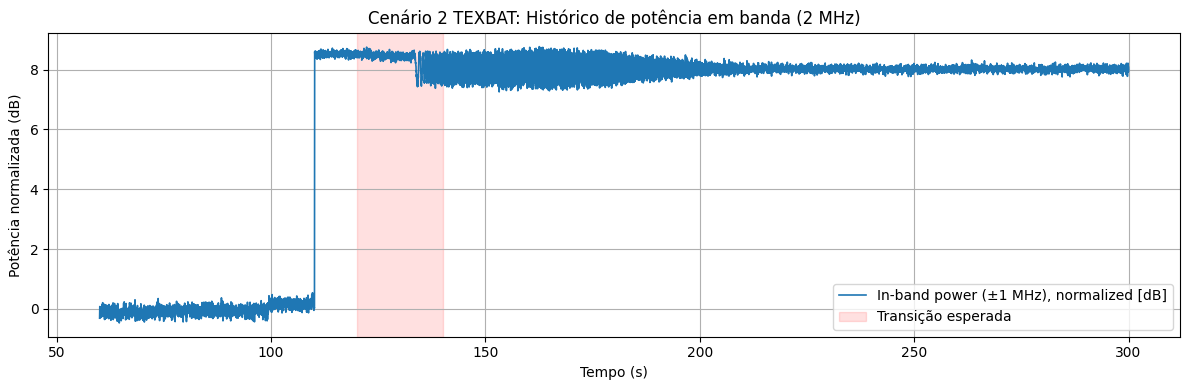

Delta dB (pós - pré): 8.027959503930937 dB


In [3]:
# 1) Time history of normalized in-band (±1 MHz) power, 60–160 s
# Strategy: sample ~800 time points; each point reads a short window (32768 samples ≈ 1.31 ms)
# and integrates PSD within ±1 MHz. Normalize to pre-attack median (t < 120 s) and plot in dB.

np.random.seed(0)

n_points = 10000
win_N = 32768  # keep power-of-two FFT, ~1.31 ms at 25 Msps

# time grid (inclusive of endpoints)
T = np.linspace(t_start, t_end, n_points)

power_lin = np.empty(n_points, dtype=np.float64)
power_db = np.empty(n_points, dtype=np.float64)
centroid_hz = np.empty(n_points, dtype=np.float64)
phi_lag1 = np.empty(n_points, dtype=np.float64)

for i, t in enumerate(T):
    x = read_window_at_time(float(t), win_N)
    p_lin, p_db = inband_power_2mhz(x)
    power_lin[i] = p_lin
    power_db[i] = p_db
    centroid_hz[i] = doppler_proxy_centroid(x)
    phi_lag1[i] = lag1_autocorr_phase(x)

# Normalize power to pre-attack baseline
pre_mask = T < 120.0
baseline = np.median(power_lin[pre_mask]) if np.any(pre_mask) else np.median(power_lin)
power_norm_db = 10.0 * np.log10((power_lin / (baseline + 1e-30)) + 1e-30)

fig, ax = plt.subplots(1, 1, figsize=(12, 4))
ax.plot(T, power_norm_db, '-', lw=1.2, label='In-band power (±1 MHz), normalized [dB]')
ax.axvspan(120, 140, color='r', alpha=0.12, label='Transição esperada')
ax.set_xlabel('Tempo (s)')
ax.set_ylabel('Potência normalizada (dB)')
ax.set_title('Cenário 2 TEXBAT: Histórico de potência em banda (2 MHz)')
ax.legend(); ax.grid(True)
plt.tight_layout(); plt.show()

# Quick stats around transition
print('Delta dB (pós - pré):', float(np.median(power_norm_db[T>140]) - np.median(power_norm_db[T<120])), 'dB')

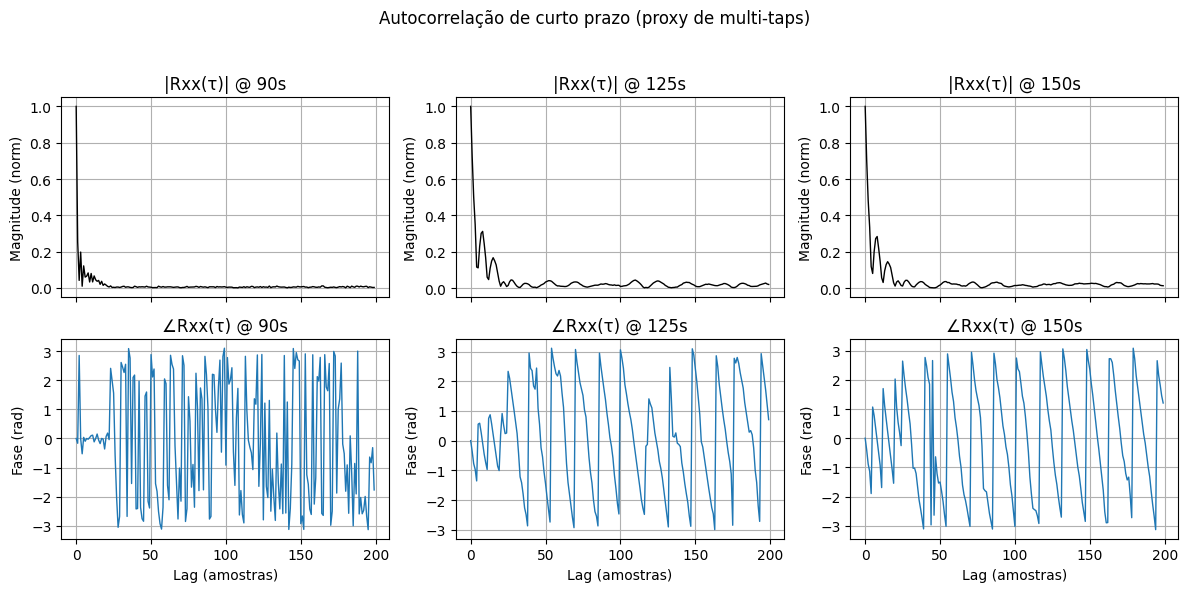

In [4]:
# 4) Correlation proxy (multi-tap) via short-time autocorrelation
# We examine autocorrelation over small lags for three times: pre, during, post
select_times = [90.0, 125.0, 150.0]  # s (adjust if needed)
win_N_corr = 65536  # ~2.62 ms window for better lag resolution
max_lag = 200  # complex lags to show (samples)

fig, axes = plt.subplots(2, len(select_times), figsize=(4*len(select_times), 6), sharex='col')
for k, t0 in enumerate(select_times):
    x = read_window_at_time(t0, win_N_corr)
    # band-limit implicitly via Hann before autocorr
    xw = x * np.hanning(len(x))
    # Biased autocorrelation via FFT (fast)
    X = np.fft.fft(xw, n=2*len(xw))
    r_full = np.fft.ifft(np.abs(X)**2)
    r = r_full[:max_lag]

    lags = np.arange(len(r))
    axes[0, k].plot(lags, np.abs(r) / (np.abs(r[0]) + 1e-20), '-k', lw=1.0)
    axes[0, k].set_title(f'|Rxx(τ)| @ {t0:.0f}s')
    axes[0, k].set_ylabel('Magnitude (norm)')
    axes[0, k].grid(True)

    axes[1, k].plot(lags, np.angle(r), '-', lw=1.0)
    axes[1, k].set_title(f'∠Rxx(τ) @ {t0:.0f}s')
    axes[1, k].set_xlabel('Lag (amostras)')
    axes[1, k].set_ylabel('Fase (rad)')
    axes[1, k].grid(True)

plt.suptitle('Autocorrelação de curto prazo (proxy de multi-taps)')
plt.tight_layout(rect=(0,0,1,0.95))

plt.show()

## Interpretação esperada (Cenário 2 TEXBAT)

- Potência em banda (±1 MHz):
  - Antes do ataque (~60–120 s), a curva normalizada deveria oscilar em torno de 0 dB.
  - Durante a transição (~120–140 s), espera-se um aumento abrupto/gradual positivo (overpower).
  - Após (~>140 s), um novo patamar (acima de 0 dB) pode se manter se o spoofer dominar.

- Proxy de Doppler (centro espectral):
  - Pré-ataque: variações pequenas em torno de 0 Hz (baseband), sem tendência comum pronunciada.
  - Transição: desvio sistemático (rampa/curva) sugerindo manobra do spoofer; valores se deslocam e depois estabilizam.
  - Pós-ataque: novo centro médio, estável.

- Proxy de perturbação de fase (lag-1 autocorr phase, z-score):
  - Pré: z-scores próximos de 0 (ruído normal do canal).
  - Transição: picos acima de 5σ indicam "phase trauma" (mudança rápida de dinâmica de fase).
  - Pós: retorno a níveis moderados, mas possivelmente com offset.

- Autocorrelação (proxy de multi-taps):
  - Pré: |Rxx(τ)| decai suave, fase sem oscilações regulares.
  - Durante: surgem ondulações/oscilações (batimentos) em |Rxx(τ)| e variações sistemáticas em ∠Rxx(τ), indicando interação entre componentes (autêntico + falso).
  - Pós: padrão diferente do pré (domínio do falso), com assinatura mais estável.

Observações e limitações:
- Estes são proxies de baixo custo computacional sobre o sinal IF/baseband. Métricas clássicas como C/N0 por canal e correlação complexa em múltiplos taps (early/prompt/late por PRN) requerem uma etapa de despreading (gerar C/A code, wipeoff de portadora, busca de Doppler) e seriam mais diagnósticas; posso adicionar uma célula de aquisição simplificada para um PRN específico se quiser.
- Assumo sinal centrado em DC; se o IF não for zero-IF, podemos recentrar (mixar) ou ajustar a máscara de frequências na integração (mudar a banda ao redor do IF conhecido).


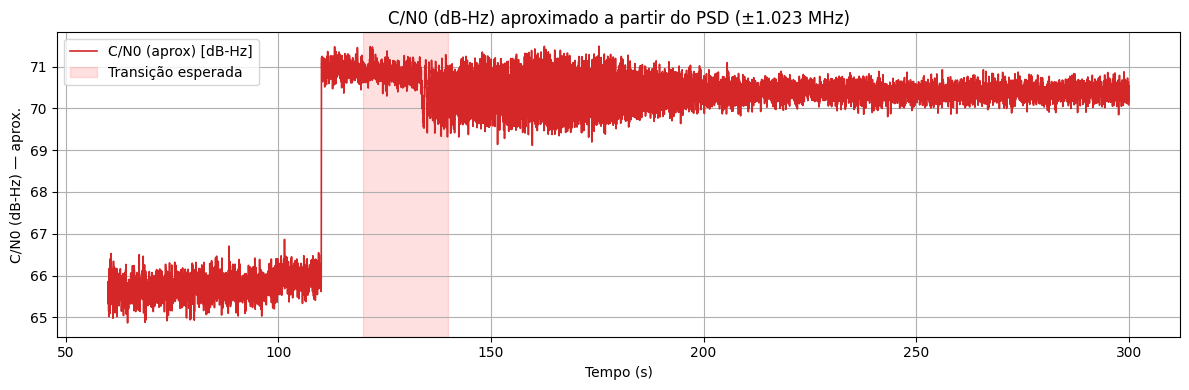

C/N0 pré (mediana, t<120s):  65.83380530671366 dB-Hz
C/N0 pós (mediana, t>140s):  70.40139578177636 dB-Hz
Δ (pós - pré):  4.567590475062701 dB-Hz


In [5]:
# 5) C/N0 (dB-Hz) — estimativa por PSD (sem despreading)
# Atenção: é uma aproximação de tendência (não absoluta), baseada em:
# - Centro espectral (fc) por centróide em ±2 MHz
# - Banda do sinal: ±1.023 MHz
# - N0 estimado nas bandas de ruído: 1.5–3.5 MHz (ambos os lados)
# Fórmula: C/N0 ≈ (P_band - N0 * B_sig) / N0  [Hz]  → 10*log10(·) em dB-Hz

win_N_cn0 = 32768  # mesmo tamanho de janela
B_sig = 2 * 1.023e6

def estimate_cn0_dbhz(x: np.ndarray) -> float:
    N = len(x)
    w = np.hanning(N).astype(np.float32)
    X = fftshift(fft(x * w))
    f = fftshift(fftfreq(N, d=1/fs))
    # Periodograma (dois lados) por Hz
    S = (np.abs(X)**2) / (fs * np.sum(w**2))
    df = f[1] - f[0]

    # Estimar fc pelo centróide em ±2 MHz
    band2 = np.abs(f) <= 2.0e6
    S2 = S[band2]
    f2 = f[band2]
    denom = np.sum(S2) + 1e-30
    fc = float(np.sum(f2 * S2) / denom)

    # Máscaras de banda do sinal e bandas de ruído
    sig_mask = np.abs(f - fc) <= 1.023e6
    noise_mask = (np.abs(f - fc) >= 1.5e6) & (np.abs(f - fc) <= 3.5e6)

    # N0 por mediana (robusto)
    if not np.any(noise_mask):
        return np.nan
    N0 = float(np.median(S[noise_mask]))

    # Potência integrada na banda do sinal
    P_band = float(np.sum(S[sig_mask]) * df)

    # C estimado e C/N0
    C_est = max(P_band - N0 * B_sig, 1e-30)
    CNo = C_est / (N0 + 1e-30)  # Hz
    return 10.0 * np.log10(CNo)

CNo_dbHz = np.empty_like(T)
for i, t in enumerate(T):
    x = read_window_at_time(float(t), win_N_cn0)
    CNo_dbHz[i] = estimate_cn0_dbhz(x)

fig, ax = plt.subplots(1,1, figsize=(12,4))
ax.plot(T, CNo_dbHz, '-', lw=1.2, color='C3', label='C/N0 (aprox) [dB-Hz]')
ax.axvspan(120, 140, color='r', alpha=0.12, label='Transição esperada')
ax.set_xlabel('Tempo (s)')
ax.set_ylabel('C/N0 (dB-Hz) — aprox.')
ax.set_title('C/N0 (dB-Hz) aproximado a partir do PSD (±1.023 MHz)')
ax.legend(); ax.grid(True)
plt.tight_layout(); plt.show()

print('C/N0 pré (mediana, t<120s): ', float(np.nanmedian(CNo_dbHz[T<120])), 'dB-Hz')
print('C/N0 pós (mediana, t>140s): ', float(np.nanmedian(CNo_dbHz[T>140])), 'dB-Hz')
print('Δ (pós - pré): ', float(np.nanmedian(CNo_dbHz[T>140]) - np.nanmedian(CNo_dbHz[T<120])), 'dB-Hz')

## Notas sobre a estimativa de C/N0

- Esta métrica é aproximada porque não fazemos despreading por PRN (onde C é realmente a potência pós-correlação). Mesmo assim, ela é útil para ver tendências: durante o overpower do spoofer, o valor estimado de C/N0 sobe.
- Se o IF não for zero-IF, a detecção de fc por centróide compensa descentragens moderadas. Se houver interferência narrowband, troque a mediana por média truncada nas bandas de ruído.
- Para C/N0 absoluto por satélite, o caminho correto é: gerar C/A code de um PRN, wipeoff de portadora com um Doppler, correlacionar (early/prompt/late) e aplicar estimadores clássicos (por exemplo, relação entre sinal e ruído nos correlators). Posso adicionar essa etapa para um PRN de interesse.


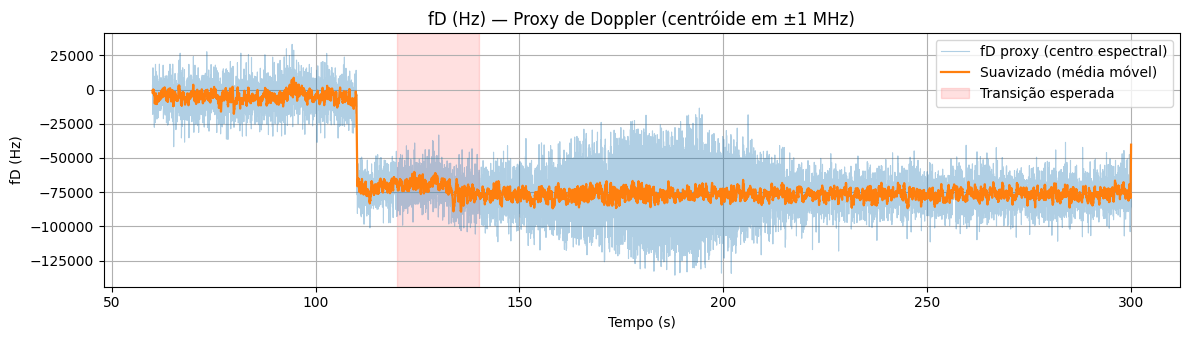

fD pré (mediana, t<120s):  -7951.817904793463 Hz
fD pós (mediana, t>140s):  -76549.47059604974 Hz
Δ fD (pós - pré):  -68597.65269125627 Hz


In [6]:
# fD (Hz) — Proxy de Doppler via centróide espectral (±1 MHz)
# Reusa centroid_hz e T; se não existirem, calcula rapidamente.
try:
    _ = centroid_hz
    _ = T
    _ = win_N
except NameError:
    n_points = 800
    win_N = 32768
    T = np.linspace(t_start, t_end, n_points)
    centroid_hz = np.empty(n_points, dtype=np.float64)
    for i, t in enumerate(T):
        x = read_window_at_time(float(t), win_N)
        centroid_hz[i] = doppler_proxy_centroid(x)

# Suavização leve para visualização
w = 11 if len(centroid_hz) >= 11 else (len(centroid_hz) // 5 * 2 + 1)
if w and w >= 3 and w % 2 == 1:
    k = np.ones(w) / w
    centroid_smooth = np.convolve(centroid_hz, k, mode='same')
else:
    centroid_smooth = centroid_hz.copy()

fig, ax = plt.subplots(1,1, figsize=(12,3.5))
ax.plot(T, centroid_hz, color='C0', alpha=0.35, lw=0.8, label='fD proxy (centro espectral)')
ax.plot(T, centroid_smooth, color='C1', lw=1.6, label='Suavizado (média móvel)')
ax.axvspan(120, 140, color='r', alpha=0.12, label='Transição esperada')
ax.set_xlabel('Tempo (s)')
ax.set_ylabel('fD (Hz)')
ax.set_title('fD (Hz) — Proxy de Doppler (centróide em ±1 MHz)')
ax.legend(); ax.grid(True)
plt.tight_layout(); plt.show()

print('fD pré (mediana, t<120s): ', float(np.median(centroid_hz[T<120])), 'Hz')
print('fD pós (mediana, t>140s): ', float(np.median(centroid_hz[T>140])), 'Hz')
print('Δ fD (pós - pré): ', float(np.median(centroid_hz[T>140]) - np.median(centroid_hz[T<120])), 'Hz')

## O que mede o Phase Trauma Flag?

O gráfico indica momentos em que há "trauma de fase": perturbações abruptas na fase da portadora durante captura/engate/pull‑off do spoofer. Em um receptor GNSS, isso aparece como saltos ou mudanças rápidas na saída do discriminador de fase do PLL (ou na derivada da fase). Aqui, como estamos no IF/baseband bruto (sem rastrear PRNs), usamos um proxy:

- Em pequenas janelas, desembrulhamos a fase φ[n] = unwrap(angle(x[n])).
- Ajustamos uma reta φ̂(t) = m t + b para remover a tendência (Doppler). O coeficiente m dá a frequência instantânea média (Hz).
- Medimos: (1) o desvio do slope (m) em relação à linha de base pré‑ataque e (2) a dispersão do resíduo r = φ − φ̂.
- Sinalizamos "trauma" quando z‑scores desses indicadores excedem limiares por algumas janelas consecutivas.

Isso reproduz o espírito da figura: picos binários onde a dinâmica de fase sai do regime normal. Para valores absolutos por canal, seria necessário rastrear um PRN (PLL real).

In [7]:
# Helpers: gerar código C/A GPS L1 para um PRN e correlacionar
# Referência simplificada: gerador de G1/G2 taps padrão; NÃO cobre sinais modernos.

def ca_code(prn: int) -> np.ndarray:
    # Implementação mínima de G1/G2 conforme ICD-GPS-200
    # Taps G1: [3,10]; G2 taps dependem do PRN conforme tabela; forneceremos mapa parcial.
    g2_tap_map = {
        1: (2,6), 2: (3,7), 3: (4,8), 4: (5,9), 5: (1,9), 6: (2,10), 7: (1,8), 8: (2,9), 9: (3,10), 10: (2,3),
        11: (3,4), 12: (5,6), 13: (6,7), 14: (7,8), 15: (8,9), 16: (9,10), 17: (1,4), 18: (2,5), 19: (3,6), 20: (4,7)
    }
    if prn not in g2_tap_map:
        raise ValueError('PRN fora do conjunto simplificado (1-20)')
    t1, t2 = g2_tap_map[prn]
    g1 = np.ones(10, dtype=np.int8)
    g2 = np.ones(10, dtype=np.int8)
    code = np.empty(1023, dtype=np.int8)
    for i in range(1023):
        g1_out = g1[-1]
        g2_out = (g2[-t1] ^ g2[-t2])  # xor taps específicos
        code[i] = g1_out ^ g2_out
        # feedback bits
        fb1 = g1[2] ^ g1[9]
        fb2 = g2[1] ^ g2[2] ^ g2[5] ^ g2[7] ^ g2[8] ^ g2[9]
        g1[1:] = g1[:-1]; g1[0] = fb1
        g2[1:] = g2[:-1]; g2[0] = fb2
    # Mapear {0,1} -> {+1,-1}
    return 1 - 2*code  # 1-> -1, 0-> +1 invertido para correlator convencional

# Gerar código amostrado para 1 ms em fs (sem oversampling adicional)

def sampled_code(prn: int, fs: float) -> np.ndarray:
    ca = ca_code(prn)
    chips = 1023
    # cada chip dura Tc = 1ms/1023
    Tc = 1e-3 / chips
    N = int(fs * 1e-3)  # número de amostras em 1 ms
    # índice fracionário de chip para cada amostra
    t = np.arange(N, dtype=np.float64) / fs
    chip_idx = np.floor(t / Tc).astype(int)
    chip_idx = np.clip(chip_idx, 0, chips-1)
    return ca[chip_idx].astype(np.float32)

# Ler bloco de dados bruto a partir de offset de amostra complexa

def read_block(start_sample: int, block_N: int) -> np.ndarray:
    start = max(0, min(N_samples-1, start_sample))
    end = min(N_samples, start + block_N)
    seg = mm[2*start:2*end]
    I = seg[0::2].astype(np.float32)
    Q = seg[1::2].astype(np.float32)
    return I + 1j*Q


In [8]:
# Aquisição simples de um PRN (varredura grosseira de Doppler)
# Estratégia: usar 10 ms (10 blocos de 1 ms) para não-coerente.

def acquire_prn(prn: int, t_center_s: float, doppler_bins=np.arange(-5000, 5001, 500)):
    code_1ms = sampled_code(prn, fs)
    N1 = len(code_1ms)
    code_fft = np.conj(np.fft.fft(code_1ms))  # conjugado para correlator via FFT

    # 10 ms de dados
    span_ms = 10
    total_samples = span_ms * N1
    start_sample = int(t_center_s * fs) - total_samples//2
    x = read_block(start_sample, total_samples)
    if len(x) < total_samples:
        return None

    metrics = []
    best = {'snr': -np.inf}
    # dividir em 10 blocos de 1 ms
    for fd in doppler_bins:
        # gerar correção de portadora para todos os samples
        n = np.arange(total_samples, dtype=np.float64)
        carr = np.exp(-1j * 2*np.pi * fd * n / fs)
        y = x * carr
        sums = []
        for k in range(span_ms):
            seg = y[k*N1:(k+1)*N1]
            Y = np.fft.fft(seg)
            R = np.fft.ifft(Y * code_fft)
            # métrica: pico de magnitude
            mag = np.abs(R)
            peak = np.max(mag)
            noise_floor = np.median(mag)
            snr = (peak - noise_floor) / (noise_floor + 1e-9)
            sums.append((peak, snr, np.argmax(mag)))
        # não-coerente: somar picos (ou soma de SNR)
        total_peak = sum(p for p,_,_ in sums)
        total_snr = sum(s for _,s,_ in sums)
        avg_code_phase = int(np.median([cp for _,_,cp in sums]))
        if total_snr > best['snr']:
            best = {'snr': total_snr, 'fd': fd, 'code_phase': avg_code_phase, 'total_peak': total_peak}
    return best

# Exemplo de uso (ajuste PRN):
# result = acquire_prn(prn=1, t_center_s=100.0)
# print(result)


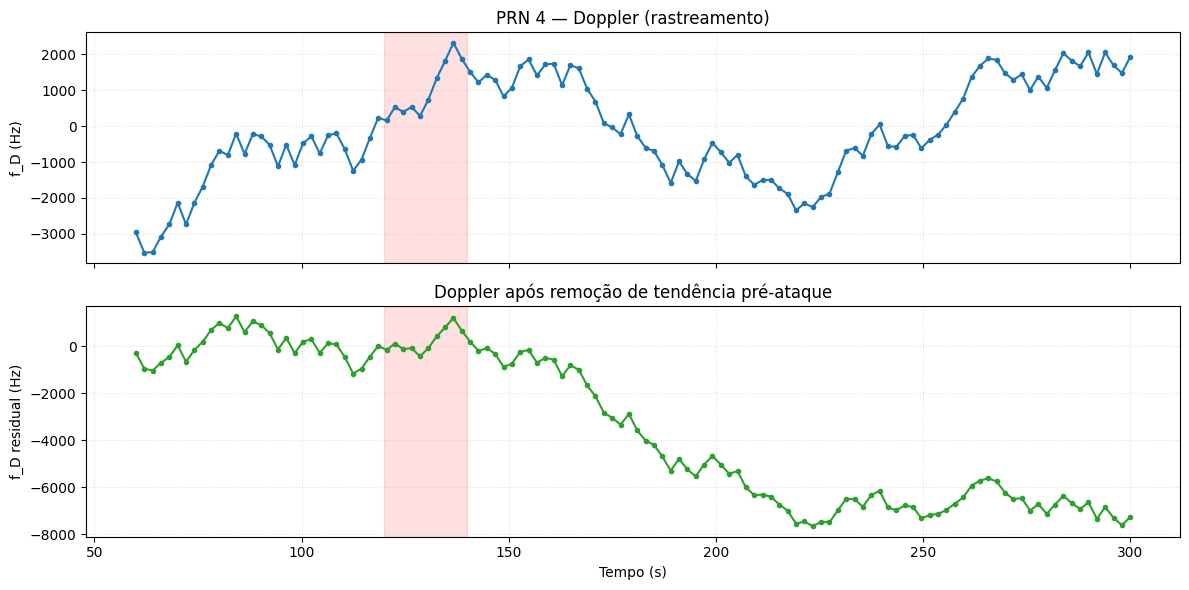

In [9]:
# Time-series de Doppler e C/N0 aproximado para um PRN específico (com rastreamento e refinamento)
# Ideia: 1) busca grosseira só no primeiro ponto; 2) depois, busca fina ao redor do fd anterior
# com passo pequeno e interpolação parabólica para suavizar a quantização dos bins.

from typing import Tuple

def _best_fd_with_span(prn: int, t_center_s: float, doppler_bins: np.ndarray, span_ms: int = 10) -> Tuple[float, float]:
    """Retorna (fd_est_Hz, cn0_like_dB) para um conjunto de bins e janela de span_ms.
    Implementa o mesmo correlator via FFT de 1 ms repetido 'span_ms' vezes (não-coerente).
    """
    # Código 1 ms
    code_1ms = sampled_code(prn, fs)
    N1 = len(code_1ms)
    code_fft = np.conj(np.fft.fft(code_1ms))

    total_samples = span_ms * N1
    start_sample = int(t_center_s * fs) - total_samples//2
    x = read_block(start_sample, total_samples)
    if len(x) < total_samples:
        return np.nan, np.nan

    # Pré-criar índices e buffers
    n = np.arange(total_samples, dtype=np.float64)

    # Vamos guardar a métrica para cada fd (pico somado)
    peaks_per_fd = []

    for fd in doppler_bins:
        carr = np.exp(-1j * 2*np.pi * fd * n / fs)
        y = x * carr
        total_peak = 0.0
        # dividir em blocos de 1 ms
        for k in range(span_ms):
            seg = y[k*N1:(k+1)*N1]
            Y = np.fft.fft(seg)
            R = np.fft.ifft(Y * code_fft)
            mag = np.abs(R)
            peak = float(np.max(mag))
            total_peak += peak
        peaks_per_fd.append(total_peak)

    peaks_per_fd = np.asarray(peaks_per_fd, dtype=np.float64)
    i_best = int(np.argmax(peaks_per_fd))

    # Interpolação parabólica em 3 pontos para suavizar quantização de bin
    fd_est = float(doppler_bins[i_best])
    if 0 < i_best < len(doppler_bins)-1:
        y1, y2, y3 = peaks_per_fd[i_best-1], peaks_per_fd[i_best], peaks_per_fd[i_best+1]
        denom = (y1 - 2*y2 + y3)
        if abs(denom) > 1e-12:
            delta = 0.5*(y1 - y3)/denom  # deslocamento em unidades de bin
            fd_est = float(doppler_bins[i_best] + delta*(doppler_bins[1]-doppler_bins[0]))

    # C/N0-like em dB a partir do pico somado (proxy)
    cn0_like_db = 10*np.log10(peaks_per_fd[i_best] + 1e-9)
    return fd_est, float(cn0_like_db)


def prn_timeseries_tracked(
    prn: int,
    t0: float = 60.0,
    t1: float = 250.0,
    n_points: int = 120,
    coarse_range_hz: int = 6000,
    coarse_step_hz: int = 500,
    fine_span_hz: int = 600,
    fine_step_hz: int = 50,
    span_ms_init: int = 10,
    span_ms_fine: int = 10,
):
    """Time-series de Doppler com rastreamento.
    - Primeiro ponto: varredura grosseira ±coarse_range com coarse_step e refinamento local fino.
    - Pontos seguintes: apenas busca fina em torno de fd anterior (±fine_span) com fine_step.
    Retorna: times, fd_est (Hz), cn0_like (dB, proxy)
    """
    times = np.linspace(t0, t1, n_points)
    fd_est_list = []
    cn0_list = []
    prev_fd = None

    for i, t in enumerate(times):
        if i == 0 or prev_fd is None or not np.isfinite(prev_fd):
            # Coarse
            coarse_bins = np.arange(-coarse_range_hz, coarse_range_hz+1, coarse_step_hz)
            fd0, cn0db0 = _best_fd_with_span(prn, t, coarse_bins, span_ms=span_ms_init)
            if not np.isfinite(fd0):
                fd_est_list.append(np.nan); cn0_list.append(np.nan); prev_fd = None; continue
            # Refino local
            fine_bins = np.arange(int(fd0 - fine_span_hz), int(fd0 + fine_span_hz)+1, fine_step_hz)
            fd1, cn0db1 = _best_fd_with_span(prn, t, fine_bins, span_ms=span_ms_fine)
            fd_best = fd1 if np.isfinite(fd1) else fd0
            cn0_best = cn0db1 if np.isfinite(fd1) else cn0db0
        else:
            # Somente fino ao redor do anterior
            fine_bins = np.arange(int(prev_fd - fine_span_hz), int(prev_fd + fine_span_hz)+1, fine_step_hz)
            fd_best, cn0_best = _best_fd_with_span(prn, t, fine_bins, span_ms=span_ms_fine)
            if not np.isfinite(fd_best):
                # fallback grossa rara
                coarse_bins = np.arange(-coarse_range_hz, coarse_range_hz+1, coarse_step_hz)
                fd_best, cn0_best = _best_fd_with_span(prn, t, coarse_bins, span_ms=span_ms_init)

        fd_est_list.append(fd_best)
        cn0_list.append(cn0_best)
        prev_fd = fd_best

    return times, np.array(fd_est_list), np.array(cn0_list)

# Executar para um PRN (ajuste 'prn' se quiser outro)
prn = 4
# Série temporal
times_prn, fd_prn, cn0_prn = prn_timeseries_tracked(prn, t0=60, t1=300, n_points=120,
                                                    coarse_range_hz=6000, coarse_step_hz=500,
                                                    fine_span_hz=600, fine_step_hz=50,
                                                    span_ms_init=10, span_ms_fine=10)

# Visualização: Doppler bruto e Doppler residual (detrendido pelo pré-ataque < 120 s)
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(times_prn, fd_prn, '-o', ms=3, label='fd estimado')
ax[0].axvspan(120, 140, color='r', alpha=0.12)
ax[0].set_ylabel('f_D (Hz)')
ax[0].set_title(f'PRN {prn} — Doppler (rastreamento)')
ax[0].grid(True, ls=':', alpha=0.4)

# Detrend usando janela pré-ataque
pre_mask = times_prn < 120
if np.any(pre_mask) and np.isfinite(fd_prn[pre_mask]).sum() >= 3:
    m, b = np.polyfit(times_prn[pre_mask], fd_prn[pre_mask], 1)
    fd_fit = m*times_prn + b
    fd_resid = fd_prn - fd_fit
else:
    fd_fit = np.nan*np.zeros_like(fd_prn)
    fd_resid = np.nan*np.zeros_like(fd_prn)

ax[1].plot(times_prn, fd_resid, '-o', ms=3, color='C2', label='residual')
ax[1].axvspan(120, 140, color='r', alpha=0.12)
ax[1].set_ylabel('f_D residual (Hz)')
ax[1].set_xlabel('Tempo (s)')
ax[1].set_title('Doppler após remoção de tendência pré-ataque')
ax[1].grid(True, ls=':', alpha=0.4)

plt.tight_layout(); plt.show()
